# DermAI - Dataset Audit and Exploratory Data Analysis

## Project Objective
To perform systematic exploratory data analysis and quality assessment
of PAD-UFES-20 and Fitzpatrick17k datasets.

## Datasets
1. PAD-UFES-20
2. Fitzpatrick17k

## Analysis
- Dataset structure and metadata inspection
- Image-to-metadata matching
- Missing and duplicate records
- Disease class distribution
- Fitzpatrick skin-type distribution
- Image dimensions and quality assessment
- Patient-level data leakage investigation

**Note:** Both datasets are initially analyzed independently.

In [1]:
import os
import sys
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path
from PIL import Image, ImageStat
from collections import Counter

import warnings
warnings.filterwarnings("ignore")

PROJECT_ROOT = Path.cwd()

# If notebook is launched from another directory, locate project root
if not (PROJECT_ROOT / "ml").exists():
    PROJECT_ROOT = Path.cwd().parent.parent

PAD_DIR = PROJECT_ROOT / "ml/datasets/raw/pad_ufes_20"
FITZ_DIR = PROJECT_ROOT / "ml/datasets/raw/fitzpatrick17k"

PAD_CSV = PAD_DIR / "metadata.csv"
FITZ_CSV = FITZ_DIR / "fitzpatrick17k.csv"

IMAGE_DIR = PAD_DIR / "images"

print("Python:", sys.version)
print("Project Root:", PROJECT_ROOT)
print("PAD Dataset:", PAD_DIR)
print("Fitzpatrick Dataset:", FITZ_DIR)

assert PAD_CSV.exists(), "PAD metadata.csv not found!"
assert FITZ_CSV.exists(), "Fitzpatrick17k.csv not found!"
assert IMAGE_DIR.exists(), "PAD images folder not found!"

print("\nAll dataset paths verified successfully!")

Matplotlib is building the font cache; this may take a moment.


Python: 3.11.18 (main, Oct 25 2026, 19:41:29) [Clang 21.0.0 (clang-2100.3.34.2)]
Project Root: /Users/abhinavswami/DERM AI
PAD Dataset: /Users/abhinavswami/DERM AI/ml/datasets/raw/pad_ufes_20
Fitzpatrick Dataset: /Users/abhinavswami/DERM AI/ml/datasets/raw/fitzpatrick17k

All dataset paths verified successfully!


In [2]:
pad_df = pd.read_csv(PAD_CSV)
fitz_df = pd.read_csv(FITZ_CSV)

print("PAD-UFES-20 Shape:", pad_df.shape)
print("Fitzpatrick17k Shape:", fitz_df.shape)

print("\nPAD-UFES-20 Columns:")
print(pad_df.columns.tolist())

print("\nFitzpatrick17k Columns:")
print(fitz_df.columns.tolist())

PAD-UFES-20 Shape: (2298, 26)
Fitzpatrick17k Shape: (16577, 9)

PAD-UFES-20 Columns:
['patient_id', 'lesion_id', 'smoke', 'drink', 'background_father', 'background_mother', 'age', 'pesticide', 'gender', 'skin_cancer_history', 'cancer_history', 'has_piped_water', 'has_sewage_system', 'fitspatrick', 'region', 'diameter_1', 'diameter_2', 'diagnostic', 'itch', 'grew', 'hurt', 'changed', 'bleed', 'elevation', 'img_id', 'biopsed']

Fitzpatrick17k Columns:
['md5hash', 'fitzpatrick_scale', 'fitzpatrick_centaur', 'label', 'nine_partition_label', 'three_partition_label', 'qc', 'url', 'url_alphanum']


In [3]:
print("PAD DATASET INFORMATION")
print("=" * 50)

display(pad_df.head())

print("\nDataset Information:")
pad_df.info()

print("\nMissing Values:")
display(pad_df.isnull().sum().sort_values(ascending=False))

print("\nDuplicate Rows:", pad_df.duplicated().sum())

print("\nUnique Patients:", pad_df["patient_id"].nunique())
print("Unique Lesions:", pad_df["lesion_id"].nunique())
print("Unique Images:", pad_df["img_id"].nunique())

PAD DATASET INFORMATION


,patient_id,lesion_id,smoke,drink,background_father,background_mother,age,pesticide,gender,skin_cancer_history,...,diameter_2,diagnostic,itch,grew,hurt,changed,bleed,elevation,img_id,biopsed
0,PAT_1516,1765,NaN,NaN,NaN,NaN,8,NaN,NaN,NaN,...,NaN,NEV,False,False,False,False,False,False,PAT_1516_1765_530.png,False
1,PAT_46,881,False,False,POMERANIA,POMERANIA,55,False,FEMALE,True,...,5.0,BCC,True,True,False,True,True,True,PAT_46_881_939.png,True
2,PAT_1545,1867,NaN,NaN,NaN,NaN,77,NaN,NaN,NaN,...,NaN,ACK,True,False,False,False,False,False,PAT_1545_1867_547.png,False
3,PAT_1989,4061,NaN,NaN,NaN,NaN,75,NaN,NaN,NaN,...,NaN,ACK,True,False,False,False,False,False,PAT_1989_4061_934.png,False
4,PAT_684,1302,False,True,POMERANIA,POMERANIA,79,False,MALE,True,...,5.0,BCC,True,True,False,False,True,True,PAT_684_1302_588.png,True



Dataset Information:
<class 'pandas.DataFrame'>
RangeIndex: 2298 entries, 0 to 2297
Data columns (total 26 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   patient_id           2298 non-null   str    
 1   lesion_id            2298 non-null   int64  
 2   smoke                1494 non-null   object 
 3   drink                1494 non-null   object 
 4   background_father    1480 non-null   str    
 5   background_mother    1476 non-null   str    
 6   age                  2298 non-null   int64  
 7   pesticide            1494 non-null   object 
 8   gender               1494 non-null   str    
 9   skin_cancer_history  1494 non-null   object 
 10  cancer_history       1494 non-null   object 
 11  has_piped_water      1494 non-null   object 
 12  has_sewage_system    1494 non-null   object 
 13  fitspatrick          1494 non-null   float64
 14  region               2298 non-null   str    
 15  diameter_1           1494 n

background_mother      822
background_father      818
fitspatrick            804
cancer_history         804
diameter_2             804
diameter_1             804
has_sewage_system      804
has_piped_water        804
skin_cancer_history    804
gender                 804
pesticide              804
drink                  804
smoke                  804
grew                     0
img_id                   0
elevation                0
bleed                    0
changed                  0
hurt                     0
patient_id               0
itch                     0
diagnostic               0
region                   0
lesion_id                0
age                      0
biopsed                  0
dtype: int64


Duplicate Rows: 0

Unique Patients: 1373
Unique Lesions: 1641
Unique Images: 2298


In [5]:
# IMAGE-TO-METADATA MATCHING

from pathlib import Path

image_extensions = {".jpg", ".jpeg", ".png"}

image_paths = [
    p for p in IMAGE_DIR.rglob("*")
    if p.is_file() and p.suffix.lower() in image_extensions
]

image_df = pd.DataFrame({
    "image_path": image_paths,
    "image_name": [p.name for p in image_paths],
    "image_id": [p.name for p in image_paths]
})

print("Total actual images:", len(image_df))

print("\nImages per folder:")
print(image_df["image_path"].apply(
    lambda p: p.parent.name
).value_counts())

# Normalize metadata IDs without changing original CSV
metadata_ids = set(
    pad_df["img_id"]
    .dropna()
    .astype(str)
    .str.strip()
    .map(lambda x: Path(x).name)
)

# Actual filenames including extensions
file_ids = set(image_df["image_name"].astype(str))

matched_ids = metadata_ids.intersection(file_ids)

missing_images = metadata_ids - file_ids
unlisted_images = file_ids - metadata_ids

print("\nIMAGE MATCHING REPORT")
print("=" * 40)

print("Metadata image IDs:", len(metadata_ids))
print("Actual image IDs:", len(file_ids))
print("Matched IDs:", len(matched_ids))
print("Missing image IDs:", len(missing_images))
print("Unlisted image IDs:", len(unlisted_images))

print("\nSample missing IDs:", list(missing_images)[:10])
print("Sample unlisted IDs:", list(unlisted_images)[:10])

assert len(matched_ids) == len(metadata_ids), \
    "Some metadata images are not matched!"

print("\nSUCCESS: Image matching completed!")

Total actual images: 2298

Images per folder:
image_path
imgs_part_1    911
imgs_part_3    728
imgs_part_2    659
Name: count, dtype: int64

IMAGE MATCHING REPORT
Metadata image IDs: 2298
Actual image IDs: 2298
Matched IDs: 2298
Missing image IDs: 0
Unlisted image IDs: 0

Sample missing IDs: []
Sample unlisted IDs: []

SUCCESS: Image matching completed!


In [6]:
# PAD-UFES-20 DISEASE CLASS DISTRIBUTION

class_counts = pad_df["diagnostic"].value_counts()

print("DISEASE CLASS DISTRIBUTION")
print("=" * 45)

display(
    pd.DataFrame({
        "Image Count": class_counts,
        "Percentage": (
            class_counts / len(pad_df) * 100
        ).round(2)
    })
)

print("\nTotal Classes:", pad_df["diagnostic"].nunique())
print("Largest Class:", class_counts.idxmax())
print("Smallest Class:", class_counts.idxmin())

DISEASE CLASS DISTRIBUTION


,Image Count,Percentage
diagnostic,,
BCC,845,36.77
ACK,730,31.77
NEV,244,10.62
SEK,235,10.23
SCC,192,8.36
MEL,52,2.26



Total Classes: 6
Largest Class: BCC
Smallest Class: MEL


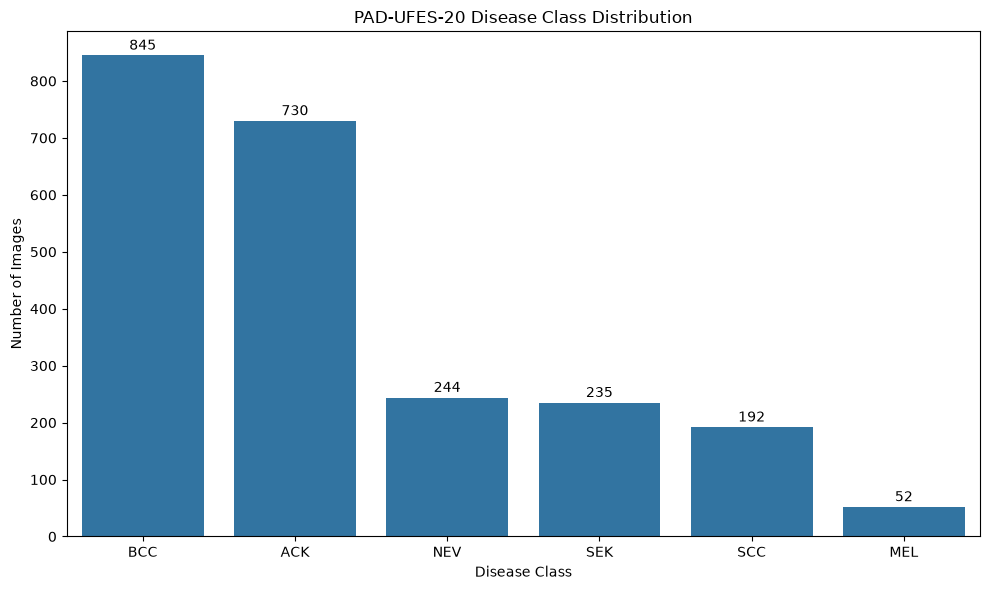

In [7]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=class_counts.index,
    y=class_counts.values
)

plt.title("PAD-UFES-20 Disease Class Distribution")
plt.xlabel("Disease Class")
plt.ylabel("Number of Images")

for i, value in enumerate(class_counts.values):
    plt.text(i, value + 10, str(value), ha="center")

plt.tight_layout()
plt.show()

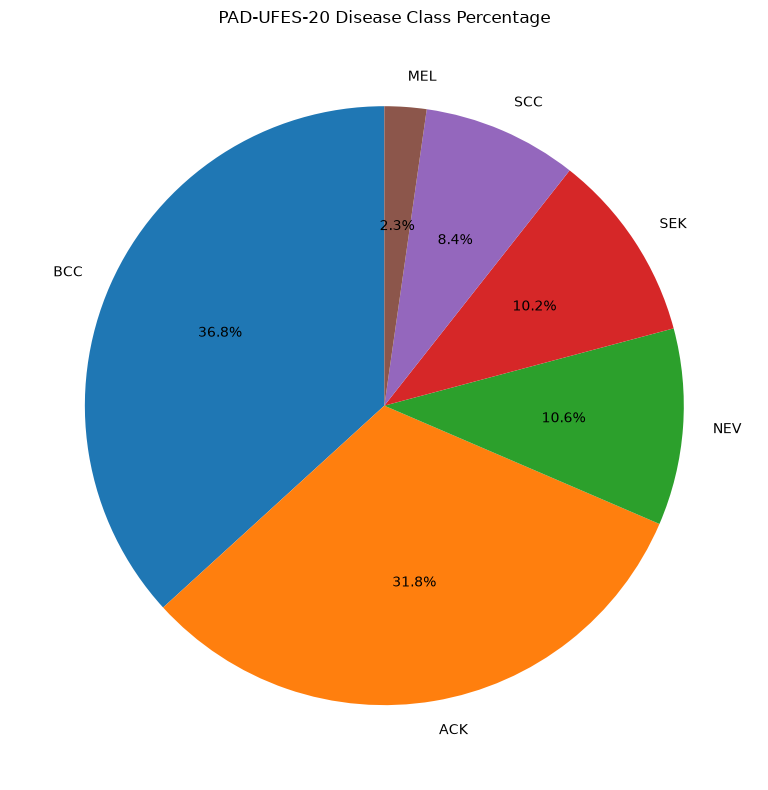

In [8]:
plt.figure(figsize=(8, 8))

plt.pie(
    class_counts.values,
    labels=class_counts.index,
    autopct="%1.1f%%",
    startangle=90
)

plt.title("PAD-UFES-20 Disease Class Percentage")
plt.tight_layout()
plt.show()

In [9]:
# FITZPATRICK SKIN TYPE DISTRIBUTION

skin_counts = fitz_df["fitzpatrick_scale"].value_counts().sort_index()

print("FITZPATRICK SKIN TYPE DISTRIBUTION")
print("=" * 45)

display(
    pd.DataFrame({
        "Image Records": skin_counts,
        "Percentage": (
            skin_counts / len(fitz_df) * 100
        ).round(2)
    })
)

print("\nUnique Skin Types:")
print(sorted(fitz_df["fitzpatrick_scale"].dropna().unique()))

FITZPATRICK SKIN TYPE DISTRIBUTION


,Image Records,Percentage
fitzpatrick_scale,,
-1,565,3.41
1,2947,17.78
2,4808,29.00
3,3308,19.96
4,2781,16.78
5,1533,9.25
6,635,3.83



Unique Skin Types:
[np.int64(-1), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6)]


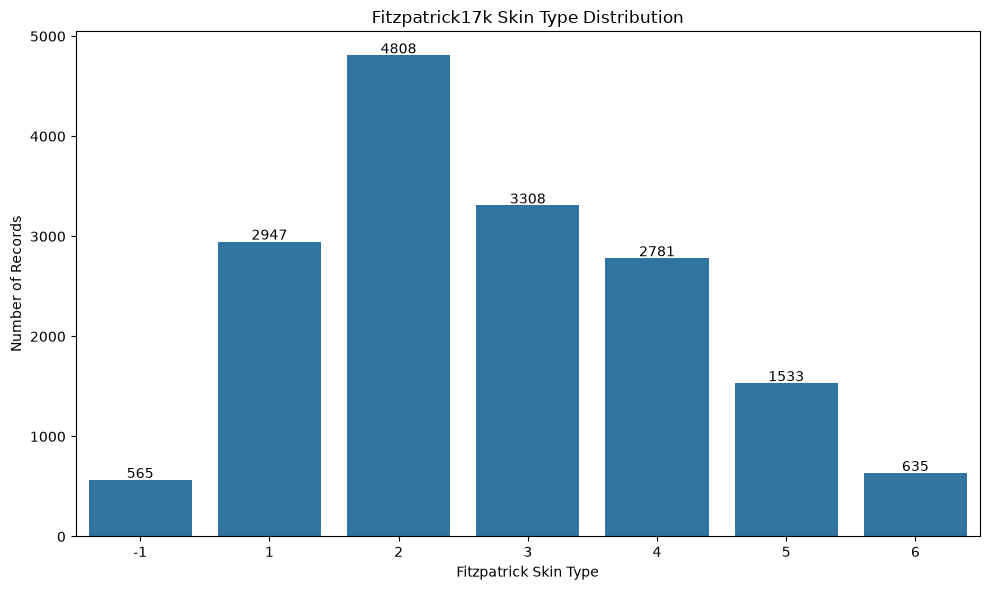

In [10]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=skin_counts.index.astype(str),
    y=skin_counts.values
)

plt.title("Fitzpatrick17k Skin Type Distribution")
plt.xlabel("Fitzpatrick Skin Type")
plt.ylabel("Number of Records")

for i, value in enumerate(skin_counts.values):
    plt.text(i, value + 20, str(value), ha="center")

plt.tight_layout()
plt.show()

In [11]:
# STEP 11: IMAGE DIMENSION AND FORMAT AUDIT

image_records = []

for image_path in image_paths:
    try:
        with Image.open(image_path) as img:
            width, height = img.size

            image_records.append({
                "image_name": image_path.name,
                "image_path": str(image_path),
                "width": width,
                "height": height,
                "format": img.format,
                "mode": img.mode,
                "file_size_kb": round(
                    image_path.stat().st_size / 1024, 2
                ),
                "readable": True
            })

    except Exception as e:
        image_records.append({
            "image_name": image_path.name,
            "image_path": str(image_path),
            "width": None,
            "height": None,
            "format": None,
            "mode": None,
            "file_size_kb": None,
            "readable": False
        })

image_audit_df = pd.DataFrame(image_records)

print("IMAGE DIMENSION AUDIT")
print("=" * 50)

print("Total Images:", len(image_audit_df))
print("Readable Images:", image_audit_df["readable"].sum())
print("Unreadable Images:", (~image_audit_df["readable"]).sum())

print("\nIMAGE DIMENSION STATISTICS")

display(
    image_audit_df[
        ["width", "height", "file_size_kb"]
    ].describe().round(2)
)

print("\nIMAGE FORMATS")
display(image_audit_df["format"].value_counts())

print("\nIMAGE MODES")
display(image_audit_df["mode"].value_counts())

print("\nMOST COMMON DIMENSIONS")

display(
    image_audit_df.groupby(
        ["width", "height"]
    ).size().sort_values(ascending=False).head(15)
)

IMAGE DIMENSION AUDIT
Total Images: 2298
Readable Images: 2298
Unreadable Images: 0

IMAGE DIMENSION STATISTICS


,width,height,file_size_kb
count,2298.00,2298.00,2298.00
mean,933.68,933.61,1532.64
std,534.60,534.67,1717.02
min,147.00,147.00,36.58
25%,528.00,527.25,435.09
50%,779.50,779.50,934.60
75%,1219.25,1218.75,2004.16
max,3474.00,3476.00,23064.57



IMAGE FORMATS


format
PNG    2298
Name: count, dtype: int64


IMAGE MODES


mode
RGBA    1440
RGB      858
Name: count, dtype: int64


MOST COMMON DIMENSIONS


width  height
750    750       75
640    640       40
1242   1242      17
1125   1125      10
542    542        6
534    534        6
2268   2268       6
433    433        6
619    619        5
757    757        5
358    358        5
750    751        5
1133   1133       5
502    502        5
549    549        5
dtype: int64

In [12]:
# STEP 12: IMAGE QUALITY ASSESSMENT

import cv2

quality_records = []

for image_path in image_paths:

    try:
        with Image.open(image_path) as img:

            # Convert to grayscale for quality measurements
            gray_img = img.convert("L")

            gray_array = np.array(gray_img)

            # Brightness: average pixel intensity
            brightness = np.mean(gray_array)

            # Contrast: standard deviation of pixel intensity
            contrast = np.std(gray_array)

            # Sharpness: variance of Laplacian
            sharpness = cv2.Laplacian(
                gray_array, cv2.CV_64F
            ).var()

            quality_records.append({
                "image_name": image_path.name,
                "brightness": brightness,
                "contrast": contrast,
                "sharpness": sharpness
            })

    except Exception as e:
        print("Error:", image_path.name, e)

quality_df = pd.DataFrame(quality_records)

print("IMAGE QUALITY ASSESSMENT")
print("=" * 50)

print("Images analyzed:", len(quality_df))

print("\nQUALITY STATISTICS")

display(
    quality_df[
        ["brightness", "contrast", "sharpness"]
    ].describe().round(2)
)

IMAGE QUALITY ASSESSMENT
Images analyzed: 2298

QUALITY STATISTICS


,brightness,contrast,sharpness
count,2298.00,2298.00,2298.00
mean,142.38,25.27,129.92
std,22.35,9.04,223.02
min,67.21,5.58,3.48
25%,127.71,18.68,27.38
50%,142.19,23.99,52.73
75%,156.98,30.28,126.17
max,219.47,64.37,3286.34


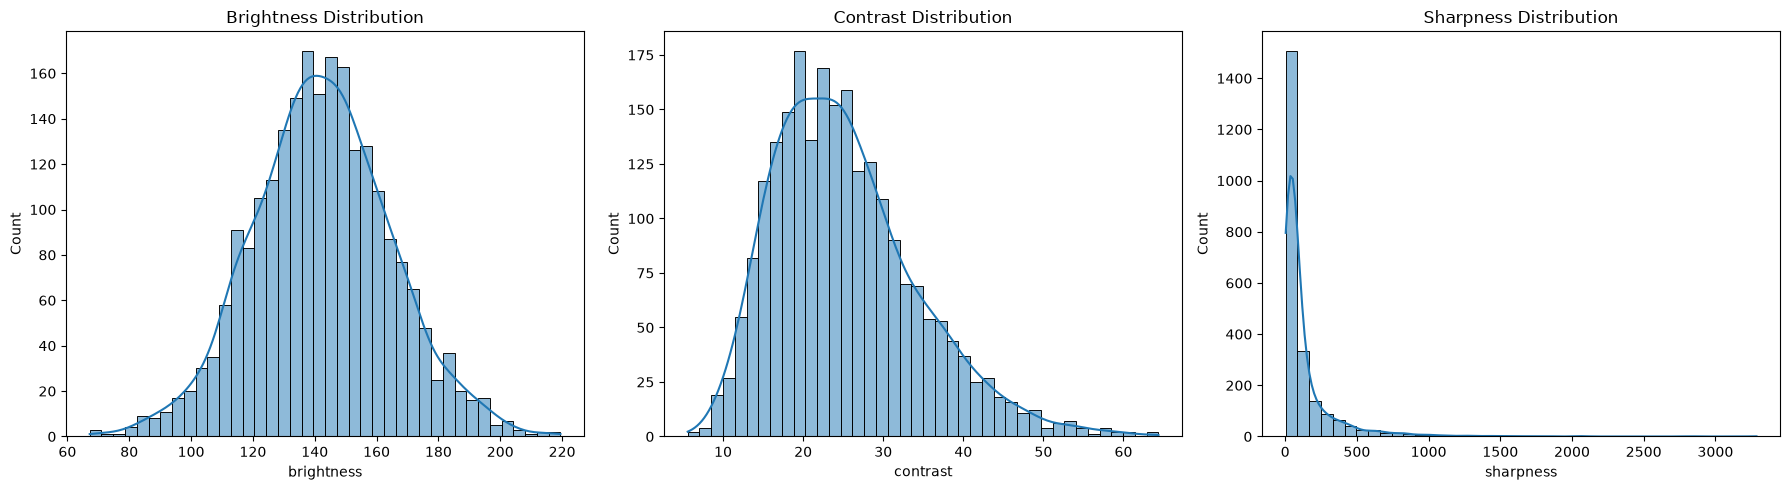

In [13]:
# STEP 13: IMAGE QUALITY DISTRIBUTION

fig, axes = plt.subplots(1, 3, figsize=(18, 5))

sns.histplot(
    quality_df["brightness"],
    bins=40,
    kde=True,
    ax=axes[0]
)
axes[0].set_title("Brightness Distribution")

sns.histplot(
    quality_df["contrast"],
    bins=40,
    kde=True,
    ax=axes[1]
)
axes[1].set_title("Contrast Distribution")

sns.histplot(
    quality_df["sharpness"],
    bins=40,
    kde=True,
    ax=axes[2]
)
axes[2].set_title("Sharpness Distribution")

plt.tight_layout()
plt.show()

In [14]:
# STEP 14: PATIENT-LEVEL AND LESION-LEVEL ANALYSIS

print("PATIENT AND LESION ANALYSIS")
print("=" * 50)

# Images belonging to each patient
patient_image_counts = (
    pad_df.groupby("patient_id")
    .agg(
        image_count=("img_id", "count"),
        lesion_count=("lesion_id", "nunique")
    )
    .sort_values("image_count", ascending=False)
)

# Images belonging to each lesion
lesion_image_counts = (
    pad_df.groupby("lesion_id")
    .agg(
        image_count=("img_id", "count"),
        patient_count=("patient_id", "nunique")
    )
    .sort_values("image_count", ascending=False)
)

print("Total unique patients:", pad_df["patient_id"].nunique())
print("Total unique lesions:", pad_df["lesion_id"].nunique())
print("Total images:", len(pad_df))

print("\nPATIENT IMAGE COUNT STATISTICS")

display(patient_image_counts["image_count"].describe())

print("\nPATIENTS WITH MOST IMAGES")

display(patient_image_counts.head(10))

print("\nLESION IMAGE COUNT STATISTICS")

display(lesion_image_counts["image_count"].describe())

print("\nLESIONS WITH MOST IMAGES")

display(lesion_image_counts.head(10))

print("\nPATIENTS WITH MULTIPLE IMAGES:",
      (patient_image_counts["image_count"] > 1).sum())

print("LESIONS WITH MULTIPLE IMAGES:",
      (lesion_image_counts["image_count"] > 1).sum())

print("LESIONS ASSOCIATED WITH MULTIPLE PATIENTS:",
      (lesion_image_counts["patient_count"] > 1).sum())

PATIENT AND LESION ANALYSIS
Total unique patients: 1373
Total unique lesions: 1641
Total images: 2298

PATIENT IMAGE COUNT STATISTICS


count    1373.000000
mean        1.673707
std         1.115038
min         1.000000
25%         1.000000
50%         1.000000
75%         2.000000
max        10.000000
Name: image_count, dtype: float64


PATIENTS WITH MOST IMAGES


,image_count,lesion_count
patient_id,,
PAT_330,10,7
PAT_388,10,6
PAT_645,10,8
PAT_747,7,3
PAT_691,7,4
PAT_115,7,4
PAT_53,7,4
PAT_1414,7,5
PAT_270,7,6



LESION IMAGE COUNT STATISTICS


count    1641.000000
mean        1.400366
std         0.686081
min         1.000000
25%         1.000000
50%         1.000000
75%         2.000000
max         8.000000
Name: image_count, dtype: float64


LESIONS WITH MOST IMAGES


,image_count,patient_count
lesion_id,,
1246,8,2
361,6,2
1286,5,2
1402,5,2
1156,4,2
322,4,1
894,4,2
1309,4,2
133,4,2



PATIENTS WITH MULTIPLE IMAGES: 544
LESIONS WITH MULTIPLE IMAGES: 512
LESIONS ASSOCIATED WITH MULTIPLE PATIENTS: 250


In [15]:
# STEP 15: INVESTIGATE SHARED LESION IDS

shared_lesion_ids = (
    lesion_image_counts[
        lesion_image_counts["patient_count"] > 1
    ].index
)

shared_lesion_records = (
    pad_df[
        pad_df["lesion_id"].isin(shared_lesion_ids)
    ][
        ["patient_id", "lesion_id", "img_id", "diagnostic"]
    ]
    .sort_values(["lesion_id", "patient_id"])
)

print("SHARED LESION ID INVESTIGATION")
print("=" * 55)

print("Shared lesion IDs:", len(shared_lesion_ids))

print("\nFIRST 30 SHARED LESION RECORDS")

display(shared_lesion_records.head(30))

print("\nPATIENTS PER SHARED LESION ID")

display(
    shared_lesion_records.groupby("lesion_id")["patient_id"]
    .nunique()
    .value_counts()
    .sort_index()
)

print("\nPATIENTS WITH MULTIPLE DISEASE LABELS")

patient_class_counts = (
    pad_df.groupby("patient_id")["diagnostic"].nunique()
)

print(
    "Patients associated with multiple diagnostic classes:",
    (patient_class_counts > 1).sum()
)

print("\nPATIENTS WITH MULTIPLE DIAGNOSTIC CLASSES")

display(
    patient_class_counts[
        patient_class_counts > 1
    ].head(20)
)

SHARED LESION ID INVESTIGATION
Shared lesion IDs: 250

FIRST 30 SHARED LESION RECORDS


,patient_id,lesion_id,img_id,diagnostic
1709,PAT_9,17,PAT_9_17_80.png,ACK
1648,PAT_998,17,PAT_998_17_641.png,SEK
1739,PAT_1000,31,PAT_1000_31_620.png,SEK
2146,PAT_21,31,PAT_21_31_965.png,NEV
37,PAT_1006,53,PAT_1006_53_716.png,ACK
1136,PAT_1006,53,PAT_1006_53_385.png,ACK
1840,PAT_38,53,PAT_38_53_198.png,BCC
255,PAT_1013,82,PAT_1013_82_876.png,ACK
584,PAT_53,82,PAT_53_82_940.png,BCC
1573,PAT_53,82,PAT_53_82_657.png,BCC



PATIENTS PER SHARED LESION ID


patient_id
2    250
Name: count, dtype: int64


PATIENTS WITH MULTIPLE DISEASE LABELS
Patients associated with multiple diagnostic classes: 179

PATIENTS WITH MULTIPLE DIAGNOSTIC CLASSES


patient_id
PAT_104     2
PAT_1064    2
PAT_1070    2
PAT_1071    2
PAT_108     2
PAT_110     2
PAT_115     2
PAT_1180    2
PAT_1184    2
PAT_1216    2
PAT_1249    2
PAT_126     2
PAT_1304    2
PAT_1305    2
PAT_1307    2
PAT_1371    2
PAT_1392    2
PAT_1393    2
PAT_1406    2
PAT_1411    2
Name: diagnostic, dtype: int64

In [16]:
# STEP 16: PATIENT-LESION DIAGNOSTIC CONSISTENCY

patient_lesion_groups = (
    pad_df.groupby(["patient_id", "lesion_id"])
    .agg(
        image_count=("img_id", "count"),
        diagnostic_count=("diagnostic", "nunique"),
        diagnostic_labels=(
            "diagnostic",
            lambda x: ", ".join(sorted(x.unique()))
        )
    )
    .reset_index()
)

print("PATIENT-LESION CONSISTENCY AUDIT")
print("=" * 55)

print("Total patient-lesion combinations:",
      len(patient_lesion_groups))

print("\nCombinations with multiple diagnostic labels:",
      (patient_lesion_groups["diagnostic_count"] > 1).sum())

print("\nCombinations with one diagnostic label:",
      (patient_lesion_groups["diagnostic_count"] == 1).sum())

print("\nPATIENT-LESION COMBINATIONS WITH MULTIPLE LABELS")

display(
    patient_lesion_groups[
        patient_lesion_groups["diagnostic_count"] > 1
    ].head(20)
)

print("\nPATIENTS WITH MULTIPLE DIAGNOSTIC CLASSES")

display(
    pad_df.groupby("patient_id")["diagnostic"]
    .nunique()
    .value_counts()
    .sort_index()
)

PATIENT-LESION CONSISTENCY AUDIT
Total patient-lesion combinations: 1891

Combinations with multiple diagnostic labels: 0

Combinations with one diagnostic label: 1891

PATIENT-LESION COMBINATIONS WITH MULTIPLE LABELS


,patient_id,lesion_id,image_count,diagnostic_count,diagnostic_labels



PATIENTS WITH MULTIPLE DIAGNOSTIC CLASSES


diagnostic
1    1194
2     166
3      10
4       3
Name: count, dtype: int64

In [17]:
# STEP 17: UNIQUE PATIENTS PER DISEASE CLASS

class_patient_counts = (
    pad_df.groupby("diagnostic")
    .agg(
        image_count=("img_id", "count"),
        unique_patients=("patient_id", "nunique"),
        unique_lesions=("lesion_id", "nunique")
    )
    .sort_values("image_count", ascending=False)
)

print("DISEASE CLASS PATIENT DISTRIBUTION")
print("=" * 55)

display(class_patient_counts)

print("\nPATIENT-LEVEL DISEASE CLASS DISTRIBUTION")

patient_class_distribution = (
    pad_df.groupby("patient_id")["diagnostic"]
    .nunique()
    .value_counts()
    .sort_index()
)

display(patient_class_distribution)

print("\nTOTAL UNIQUE PATIENTS:",
      pad_df["patient_id"].nunique())

print("TOTAL DISEASE CLASSES:",
      pad_df["diagnostic"].nunique())

DISEASE CLASS PATIENT DISTRIBUTION


,image_count,unique_patients,unique_lesions
diagnostic,,,
BCC,845,513,652
ACK,730,525,621
NEV,244,185,215
SEK,235,176,198
SCC,192,133,145
MEL,52,36,36



PATIENT-LEVEL DISEASE CLASS DISTRIBUTION


diagnostic
1    1194
2     166
3      10
4       3
Name: count, dtype: int64


TOTAL UNIQUE PATIENTS: 1373
TOTAL DISEASE CLASSES: 6


In [18]:
# STEP 18: PATIENT-SAFE STRATIFIED SPLIT TEST

from sklearn.model_selection import StratifiedGroupKFold

X = pad_df["img_id"]
y = pad_df["diagnostic"]
groups = pad_df["patient_id"]

skf = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

fold_results = []

for fold_number, (train_idx, test_idx) in enumerate(
    skf.split(X, y, groups),
    start=1
):

    train_data = pad_df.iloc[train_idx]
    test_data = pad_df.iloc[test_idx]

    train_patients = set(train_data["patient_id"])
    test_patients = set(test_data["patient_id"])

    overlap = train_patients.intersection(test_patients)

    fold_results.append({
        "Fold": fold_number,
        "Train Images": len(train_data),
        "Test Images": len(test_data),
        "Train Patients": len(train_patients),
        "Test Patients": len(test_patients),
        "Patient Overlap": len(overlap)
    })

    print(f"\nFOLD {fold_number}")
    print("-" * 45)

    print("Training class distribution:")
    display(train_data["diagnostic"].value_counts().sort_index())

    print("Testing class distribution:")
    display(test_data["diagnostic"].value_counts().sort_index())

    print("Patient overlap:", len(overlap))

print("\nFIVE-FOLD SUMMARY")
display(pd.DataFrame(fold_results))


FOLD 1
---------------------------------------------
Training class distribution:


diagnostic
ACK    584
BCC    676
MEL     42
NEV    195
SCC    153
SEK    188
Name: count, dtype: int64

Testing class distribution:


diagnostic
ACK    146
BCC    169
MEL     10
NEV     49
SCC     39
SEK     47
Name: count, dtype: int64

Patient overlap: 0

FOLD 2
---------------------------------------------
Training class distribution:


diagnostic
ACK    584
BCC    676
MEL     41
NEV    195
SCC    154
SEK    188
Name: count, dtype: int64

... (12 outputs left out)

Testing class distribution:


diagnostic
ACK    146
BCC    169
MEL     10
NEV     48
SCC     39
SEK     47
Name: count, dtype: int64

Patient overlap: 0

FIVE-FOLD SUMMARY


,Fold,Train Images,Test Images,Train Patients,Test Patients,Patient Overlap
0,1,1838,460,1100,273,0
1,2,1838,460,1096,277,0
2,3,1839,459,1097,276,0
3,4,1838,460,1099,274,0
4,5,1839,459,1100,273,0


In [19]:
# STEP 19: DATASET SPLIT CONFIGURATION

from pathlib import Path
import yaml

split_config = {
    "dataset": "PAD-UFES-20",
    "split_strategy": "StratifiedGroupKFold",
    "group_column": "patient_id",
    "label_column": "diagnostic",
    "image_column": "img_id",
    "n_splits": 5,
    "shuffle": True,
    "random_state": 42,
    "patient_leakage_prevention": True,
    "classes": sorted(pad_df["diagnostic"].unique().tolist())
}

config_path = PROJECT_ROOT / "ml" / "split_config.yaml"

with open(config_path, "w") as file:
    yaml.safe_dump(split_config, file, sort_keys=False)

print("Split configuration saved successfully!")
print("Location:", config_path)

print("\nCONFIGURATION:")
print(yaml.safe_dump(split_config, sort_keys=False))

Split configuration saved successfully!
Location: /Users/abhinavswami/DERM AI/ml/split_config.yaml

CONFIGURATION:
dataset: PAD-UFES-20
split_strategy: StratifiedGroupKFold
group_column: patient_id
label_column: diagnostic
image_column: img_id
n_splits: 5
shuffle: true
random_state: 42
patient_leakage_prevention: true
classes:
- ACK
- BCC
- MEL
- NEV
- SCC
- SEK



In [20]:
# STEP 20: GENERATE AND SAVE FIVE PATIENT-SAFE FOLDS

from pathlib import Path

SPLIT_DIR = PROJECT_ROOT / "ml" / "datasets" / "splits"
SPLIT_DIR.mkdir(parents=True, exist_ok=True)

skf = StratifiedGroupKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

for fold_number, (train_idx, test_idx) in enumerate(
    skf.split(pad_df, pad_df["diagnostic"], groups=pad_df["patient_id"]),
    start=1
):

    train_fold = pad_df.iloc[train_idx].copy()
    test_fold = pad_df.iloc[test_idx].copy()

    train_path = SPLIT_DIR / f"fold_{fold_number}_train.csv"
    test_path = SPLIT_DIR / f"fold_{fold_number}_test.csv"

    train_fold.to_csv(train_path, index=False)
    test_fold.to_csv(test_path, index=False)

    overlap = (
        set(train_fold["patient_id"])
        & set(test_fold["patient_id"])
    )

    print(f"Fold {fold_number}")
    print("Training images:", len(train_fold))
    print("Testing images:", len(test_fold))
    print("Patient overlap:", len(overlap))
    print("Saved successfully:", len(overlap) == 0)
    print("-" * 40)

print("\nAll five folds generated.")
print("Saved at:", SPLIT_DIR)

Fold 1
Training images: 1838
Testing images: 460
Patient overlap: 0
Saved successfully: True
----------------------------------------
Fold 2
Training images: 1838
Testing images: 460
Patient overlap: 0
Saved successfully: True
----------------------------------------
Fold 3
Training images: 1839
Testing images: 459
Patient overlap: 0
Saved successfully: True
----------------------------------------
Fold 4
Training images: 1838
Testing images: 460
Patient overlap: 0
Saved successfully: True
----------------------------------------
Fold 5
Training images: 1839
Testing images: 459
Patient overlap: 0
Saved successfully: True
----------------------------------------

All five folds generated.
Saved at: /Users/abhinavswami/DERM AI/ml/datasets/splits


In [21]:
# STEP 21: INDEPENDENT SPLIT VERIFICATION

verification_results = []

for fold in range(1, 6):

    train_path = SPLIT_DIR / f"fold_{fold}_train.csv"
    test_path = SPLIT_DIR / f"fold_{fold}_test.csv"

    train_df = pd.read_csv(train_path)
    test_df = pd.read_csv(test_path)

    patient_overlap = (
        set(train_df["patient_id"])
        & set(test_df["patient_id"])
    )

    image_overlap = (
        set(train_df["img_id"])
        & set(test_df["img_id"])
    )

    verification_results.append({
        "Fold": fold,
        "Train Images": len(train_df),
        "Test Images": len(test_df),
        "Patient Overlap": len(patient_overlap),
        "Image Overlap": len(image_overlap),
        "All Classes Present": (
            set(pad_df["diagnostic"].unique())
            == set(test_df["diagnostic"].unique())
        )
    })

verification_df = pd.DataFrame(verification_results)

display(verification_df)

print("\nFINAL VERIFICATION")

print(
    "All patient overlaps zero:",
    (verification_df["Patient Overlap"] == 0).all()
)

print(
    "All image overlaps zero:",
    (verification_df["Image Overlap"] == 0).all()
)

print(
    "All classes present:",
    verification_df["All Classes Present"].all()
)

print(
    "Total CSV files:",
    len(list(SPLIT_DIR.glob("*.csv")))
)

,Fold,Train Images,Test Images,Patient Overlap,Image Overlap,All Classes Present
0,1,1838,460,0,0,True
1,2,1838,460,0,0,True
2,3,1839,459,0,0,True
3,4,1838,460,0,0,True
4,5,1839,459,0,0,True



FINAL VERIFICATION
All patient overlaps zero: True
All image overlaps zero: True
All classes present: True
Total CSV files: 10


In [22]:
# STEP 22: DATASET SPLIT SUMMARY

print("=" * 55)
print("DERMAI - PAD-UFES-20 SPLIT SUMMARY")
print("=" * 55)

print("Total images:", len(pad_df))
print("Unique patients:", pad_df["patient_id"].nunique())
print("Unique patient-lesion combinations:",
      pad_df.groupby(["patient_id", "lesion_id"]).ngroups)

print("\nSplit strategy: StratifiedGroupKFold")
print("Number of folds: 5")
print("Random state: 42")
print("Grouping column: patient_id")
print("Target column: diagnostic")

print("\nDisease classes:")
for disease, count in pad_df["diagnostic"].value_counts().items():
    print(f"{disease}: {count}")

print("\nPatient leakage verification: PASSED")
print("Image leakage verification: PASSED")
print("All classes present in every test fold: PASSED")

print("\nDATASET SPLITTING COMPLETED SUCCESSFULLY!")

DERMAI - PAD-UFES-20 SPLIT SUMMARY
Total images: 2298
Unique patients: 1373
Unique patient-lesion combinations: 1891

Split strategy: StratifiedGroupKFold
Number of folds: 5
Random state: 42
Grouping column: patient_id
Target column: diagnostic

Disease classes:
BCC: 845
ACK: 730
NEV: 244
SEK: 235
SCC: 192
MEL: 52

Patient leakage verification: PASSED
Image leakage verification: PASSED
All classes present in every test fold: PASSED

DATASET SPLITTING COMPLETED SUCCESSFULLY!


In [23]:
# STEP 23: CREATE PAD-UFES-20 AUDIT REPORT

report = f"""
# DermAI - PAD-UFES-20 Dataset Audit Report

## 1. Dataset Overview

- Dataset: PAD-UFES-20
- Total images: {len(pad_df)}
- Unique patients: {pad_df['patient_id'].nunique()}
- Unique patient-lesion combinations: {pad_df.groupby(['patient_id', 'lesion_id']).ngroups}
- Metadata columns: {len(pad_df.columns)}

## 2. Disease Class Distribution

{pad_df['diagnostic'].value_counts().to_string()}

## 3. Image Matching

- Total image files: 2298
- Matched metadata records: 2298
- Missing images: 0
- Unlisted images: 0

## 4. Image Quality

- Readable images: 2298
- Unreadable images: 0
- Image formats: PNG
- Color modes: RGB and RGBA
- Image dimensions: Variable

## 5. Patient and Lesion Analysis

- Unique patients: 1373
- Unique lesions: 1641
- Patient-lesion combinations: 1891
- Combinations with conflicting diagnostic labels: 0

Note: lesion_id is not globally unique. Use the combination
(patient_id, lesion_id) for lesion-level analysis.

## 6. Cross-Validation Strategy

- Method: StratifiedGroupKFold
- Number of folds: 5
- Random state: 42
- Grouping column: patient_id
- Target column: diagnostic

## 7. Leakage Verification

- Patient overlap between train and test: 0
- Image overlap between train and test: 0
- All six classes present in every test fold: Yes

## 8. Important Considerations

- MEL is the smallest class, with only 52 images.
- Class imbalance must be considered during model training.
- Patient-level grouping must be preserved in future experiments.
- These dataset checks do not establish clinical validity or model accuracy.

## 9. Conclusion

The PAD-UFES-20 dataset has been audited for metadata,
image availability, image quality, disease distribution,
patient-level grouping, and cross-validation leakage.

Five reproducible patient-safe folds were generated
and independently verified.

This dataset is ready for the next stage of controlled
preprocessing and model experimentation.
"""

report_path = PROJECT_ROOT / "docs" / "PAD_UFES_20_AUDIT_REPORT.md"

report_path.parent.mkdir(parents=True, exist_ok=True)
report_path.write_text(report.strip(), encoding="utf-8")

print("Audit report created successfully!")
print("Location:", report_path)
print("\nReport size:", report_path.stat().st_size, "bytes")

Audit report created successfully!
Location: /Users/abhinavswami/DERM AI/docs/PAD_UFES_20_AUDIT_REPORT.md

Report size: 1845 bytes


Original image size: (372, 372)
Original image mode: RGB

Preprocessed image size: (224, 224)
Preprocessed image mode: RGB


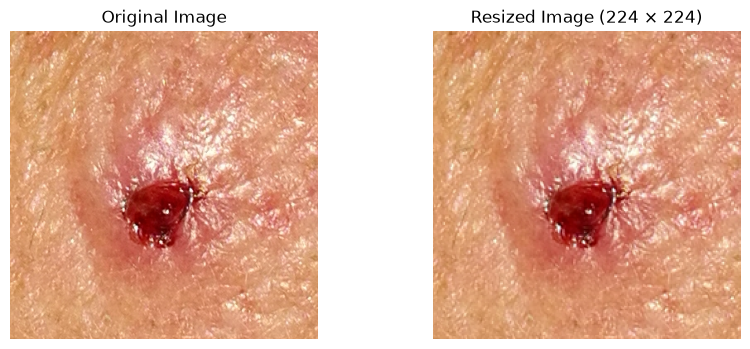

In [24]:
# STEP 2: TEST IMAGE PREPROCESSING

import sys

sys.path.insert(0, str(PROJECT_ROOT / "ml" / "src"))

from preprocessing.image_preprocessing import load_image, resize_image

# Select one actual dataset image
sample_image_path = image_paths[0]

# Load original image
original_image = load_image(sample_image_path)

# Resize image
resized_image = resize_image(original_image)

# Display results
print("Original image size:", original_image.size)
print("Original image mode:", original_image.mode)

print("\nPreprocessed image size:", resized_image.size)
print("Preprocessed image mode:", resized_image.mode)

# Display images
plt.figure(figsize=(10, 4))

plt.subplot(1, 2, 1)
plt.imshow(original_image)
plt.title("Original Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(resized_image)
plt.title("Resized Image (224 × 224)")
plt.axis("off")

plt.show()

In [25]:
# STEP 3: VERIFY IMAGE ARRAY AND PIXEL VALUES

import numpy as np

# Convert resized image into NumPy array
image_array = np.array(resized_image)

print("Image shape:", image_array.shape)
print("Data type:", image_array.dtype)

print("\nMinimum pixel value:", image_array.min())
print("Maximum pixel value:", image_array.max())

print("\nRGB channels:", image_array.shape[2])

# Validation checks
assert image_array.shape == (224, 224, 3)
assert image_array.dtype == np.uint8
assert image_array.min() >= 0
assert image_array.max() <= 255

print("\nIMAGE VALIDATION PASSED!")

Image shape: (224, 224, 3)
Data type: uint8

Minimum pixel value: 0
Maximum pixel value: 255

RGB channels: 3

IMAGE VALIDATION PASSED!


In [26]:
# STEP 4: PIXEL NORMALIZATION

# Convert pixel values from 0-255 to 0-1
normalized_image = image_array.astype(np.float32) / 255.0

print("Normalized image shape:", normalized_image.shape)
print("Data type:", normalized_image.dtype)

print("\nMinimum normalized value:", normalized_image.min())
print("Maximum normalized value:", normalized_image.max())

# Validation
assert normalized_image.shape == (224, 224, 3)
assert normalized_image.dtype == np.float32
assert normalized_image.min() >= 0.0
assert normalized_image.max() <= 1.0

print("\nPIXEL NORMALIZATION PASSED!")

Normalized image shape: (224, 224, 3)
Data type: float32

Minimum normalized value: 0.0
Maximum normalized value: 1.0

PIXEL NORMALIZATION PASSED!


In [29]:
# Reload the updated Python module

import importlib
import preprocessing.image_preprocessing as image_preprocessing

importlib.reload(image_preprocessing)

normalize_image = image_preprocessing.normalize_image

print("Module reloaded successfully!")
print("Normalization function:", normalize_image)

Module reloaded successfully!
Normalization function: <function normalize_image at 0x11fa4f100>


In [30]:
# STEP 6: VERIFY REUSABLE NORMALIZATION

normalized_result = normalize_image(resized_image)

print("Image shape:", normalized_result.shape)
print("Data type:", normalized_result.dtype)

print("\nMinimum value:", normalized_result.min())
print("Maximum value:", normalized_result.max())

assert normalized_result.shape == (224, 224, 3)
assert normalized_result.dtype == np.float32
assert normalized_result.min() >= 0.0
assert normalized_result.max() <= 1.0

print("\nREUSABLE NORMALIZATION PASSED!")

Image shape: (224, 224, 3)
Data type: float32

Minimum value: 0.0
Maximum value: 1.0

REUSABLE NORMALIZATION PASSED!


In [31]:
# STEP 7: TEST COMPLETE PREPROCESSING PIPELINE

import importlib
import preprocessing.image_preprocessing as image_preprocessing

importlib.reload(image_preprocessing)

preprocess_image = image_preprocessing.preprocess_image

processed_image = preprocess_image(sample_image_path)

print("Processed image shape:", processed_image.shape)
print("Data type:", processed_image.dtype)
print("Minimum pixel value:", processed_image.min())
print("Maximum pixel value:", processed_image.max())

assert processed_image.shape == (224, 224, 3)
assert processed_image.dtype == np.float32
assert processed_image.min() >= 0
assert processed_image.max() <= 1

print("\nCOMPLETE PREPROCESSING PIPELINE PASSED!")

Processed image shape: (224, 224, 3)
Data type: float32
Minimum pixel value: 0.0
Maximum pixel value: 1.0

COMPLETE PREPROCESSING PIPELINE PASSED!


In [32]:
# STEP 8: TEST PREPROCESSING ON 10 IMAGES

test_images = image_paths[:10]

successful_images = 0
failed_images = []

for image_path in test_images:
    try:
        processed = preprocess_image(image_path)

        assert processed.shape == (224, 224, 3)
        assert processed.dtype == np.float32
        assert processed.min() >= 0
        assert processed.max() <= 1

        successful_images += 1

    except Exception as error:
        failed_images.append((str(image_path), str(error)))

print("Total images tested:", len(test_images))
print("Successfully processed:", successful_images)
print("Failed images:", len(failed_images))

if failed_images:
    print("\nFailed image details:")
    for path, error in failed_images:
        print(path, error)

assert successful_images == len(test_images)

print("\nBATCH PREPROCESSING TEST PASSED!")


Total images tested: 10
Successfully processed: 10
Failed images: 0

BATCH PREPROCESSING TEST PASSED!


In [33]:
# STEP 9: FULL DATASET PREPROCESSING VALIDATION

from tqdm.auto import tqdm

successful_images = 0
failed_images = []

for image_path in tqdm(image_paths, desc="Testing PAD-UFES-20"):

    try:
        processed = preprocess_image(image_path)

        assert processed.shape == (224, 224, 3)
        assert processed.dtype == np.float32
        assert processed.min() >= 0
        assert processed.max() <= 1

        successful_images += 1

    except Exception as error:
        failed_images.append({
            "image": str(image_path),
            "error": str(error)
        })

print("\nFULL DATASET VALIDATION")
print("Total images:", len(image_paths))
print("Successfully processed:", successful_images)
print("Failed images:", len(failed_images))

if failed_images:
    print("\nFirst failed images:")
    for item in failed_images[:10]:
        print(item)

print("\nSUCCESS RATE:",
      round(successful_images / len(image_paths) * 100, 2), "%")

Testing PAD-UFES-20: 100%|██████████| 2298/2298 [00:48<00:00, 46.90it/s]


FULL DATASET VALIDATION
Total images: 2298
Successfully processed: 2298
Failed images: 0

SUCCESS RATE: 100.0 %


In [34]:
# STEP 10: VERIFY PREPROCESSING CONFIGURATION

import yaml

config_path = PROJECT_ROOT / "ml" / "config.yaml"

with open(config_path, "r") as file:
    preprocessing_config = yaml.safe_load(file)

print(yaml.safe_dump(preprocessing_config, sort_keys=False))
print("CONFIGURATION LOADED SUCCESSFULLY!")

dataset:
  name: PAD-UFES-20
  total_images: 2298
preprocessing:
  image_size: 224
  color_mode: RGB
  interpolation: LANCZOS
  normalization:
    method: rescale
    min_value: 0.0
    max_value: 1.0
  output_format: float32
  channels: 3
validation:
  total_images_tested: 2298
  successfully_processed: 2298
  failed_images: 0
  success_rate: 100.0

CONFIGURATION LOADED SUCCESSFULLY!


In [35]:
# STEP 14: TEST BATCH PREPROCESSING ON 10 IMAGES

import sys
import importlib

sys.path.insert(0, str(PROJECT_ROOT / "ml" / "src"))

from preprocessing import batch_preprocessing

importlib.reload(batch_preprocessing)

# Define test output directory
test_output_dir = (
    PROJECT_ROOT / "ml" / "datasets" / "processed" / "test"
)

# Process only 10 images
test_result = batch_preprocessing.process_dataset(
    metadata_path=PAD_CSV,
    image_directory=IMAGE_DIR,
    output_directory=test_output_dir,
    image_size=224,
    max_images=10
)

print("\nTEST RESULT:", test_result)
print("Saved images:", len(list(test_output_dir.glob("*.png"))))

Processing images: 100%|██████████| 10/10 [00:00<00:00, 23.34it/s]


BATCH PREPROCESSING SUMMARY
Total images: 10
Successfully processed: 10
Failed images: 0

TEST RESULT: {'total': 10, 'successful': 10, 'failed': []}
Saved images: 10


In [36]:
# STEP 15: VERIFY SAVED PROCESSED IMAGES

from PIL import Image

processed_files = list(test_output_dir.glob("*.png"))

print("Total saved files:", len(processed_files))

for file_path in processed_files[:3]:
    with Image.open(file_path) as img:
        print("\nFilename:", file_path.name)
        print("Dimensions:", img.size)
        print("Color mode:", img.mode)
        print("Format:", img.format)

        assert img.size == (224, 224)
        assert img.mode == "RGB"
        assert img.format == "PNG"

assert len(processed_files) == 10

print("\nSAVED IMAGE VERIFICATION PASSED!")

Total saved files: 10

Filename: PAT_1549_1882_230.png
Dimensions: (224, 224)
Color mode: RGB
Format: PNG

Filename: PAT_1989_4061_934.png
Dimensions: (224, 224)
Color mode: RGB
Format: PNG

Filename: PAT_117_179_983.png
Dimensions: (224, 224)
Color mode: RGB
Format: PNG

SAVED IMAGE VERIFICATION PASSED!


In [37]:
# STEP 16: PROCESS COMPLETE PAD-UFES-20 DATASET

full_output_dir = (

    PROJECT_ROOT / "ml" / "datasets" / "processed" / "pad_ufes_20"

)

full_result = batch_preprocessing.process_dataset(

    metadata_path=PAD_CSV,

    image_directory=IMAGE_DIR,

    output_directory=full_output_dir,

    image_size=224,

    max_images=None

)

print("\nFULL DATASET RESULT")

print("Total:", full_result["total"])

print("Successful:", full_result["successful"])

print("Failed:", len(full_result["failed"]))

print("Output directory:", full_output_dir)

Processing images: 100%|██████████| 2298/2298 [00:58<00:00, 39.02it/s]


BATCH PREPROCESSING SUMMARY
Total images: 2298
Successfully processed: 2298
Failed images: 0

FULL DATASET RESULT
Total: 2298
Successful: 2298
Failed: 0
Output directory: /Users/abhinavswami/DERM AI/ml/datasets/processed/pad_ufes_20


In [38]:
# STEP 17: VERIFY ALL PROCESSED IMAGES

from PIL import Image
from collections import Counter

processed_files = list(full_output_dir.glob("*.png"))

valid_images = 0
invalid_images = []

dimension_counts = Counter()
mode_counts = Counter()

for image_path in tqdm(processed_files, desc="Verifying images"):
    try:
        with Image.open(image_path) as img:
            img.load()

            if img.size != (224, 224):
                raise ValueError(f"Unexpected size: {img.size}")

            if img.mode != "RGB":
                raise ValueError(f"Unexpected mode: {img.mode}")

            valid_images += 1
            dimension_counts[img.size] += 1
            mode_counts[img.mode] += 1

    except Exception as error:
        invalid_images.append({
            "file": image_path.name,
            "error": str(error)
        })

print("\nFINAL PROCESSED DATASET VERIFICATION")
print("Total files:", len(processed_files))
print("Valid images:", valid_images)
print("Invalid images:", len(invalid_images))
print("Dimensions:", dimension_counts)
print("Color modes:", mode_counts)

assert len(processed_files) == 2298
assert valid_images == 2298
assert len(invalid_images) == 0

print("\nALL 2298 PROCESSED IMAGES VERIFIED!")

Verifying images: 100%|██████████| 2298/2298 [00:03<00:00, 636.47it/s]


FINAL PROCESSED DATASET VERIFICATION
Total files: 2298
Valid images: 2298
Invalid images: 0
Dimensions: Counter({(224, 224): 2298})
Color modes: Counter({'RGB': 2298})

ALL 2298 PROCESSED IMAGES VERIFIED!


In [39]:
# PHASE 3 - STEP 1: CHECK MODEL-READY DATASET FILES

from pathlib import Path
import pandas as pd

# Dataset paths
PROCESSED_DIR = (
    PROJECT_ROOT / "ml" / "datasets" / "processed" / "pad_ufes_20"
)

SPLITS_DIR = PROJECT_ROOT / "ml" / "datasets" / "splits"

# Find processed images
processed_images = list(PROCESSED_DIR.glob("*.png"))

# Find split CSV files
split_files = sorted(SPLITS_DIR.glob("*.csv"))

print("PROCESSED DATASET")
print("Processed images:", len(processed_images))

print("\nSPLIT FILES")
for file in split_files:
    print("-", file.name)

print("\nTOTAL SPLIT FILES:", len(split_files))

# Check expected files
assert len(processed_images) == 2298
assert len(split_files) == 10

print("\nDATASET FILE STRUCTURE VERIFIED!")

PROCESSED DATASET
Processed images: 2298

SPLIT FILES
- fold_1_test.csv
- fold_1_train.csv
- fold_2_test.csv
- fold_2_train.csv
- fold_3_test.csv
- fold_3_train.csv
- fold_4_test.csv
- fold_4_train.csv
- fold_5_test.csv
- fold_5_train.csv

TOTAL SPLIT FILES: 10

DATASET FILE STRUCTURE VERIFIED!


In [40]:
# PHASE 3 - STEP 2: PREPARE IMAGE METADATA

# Select the original metadata columns
model_df = pad_df[
    ["img_id", "patient_id", "lesion_id", "diagnostic"]
].copy()

# Add processed image paths
model_df["image_path"] = model_df["img_id"].apply(
    lambda name: str(PROCESSED_DIR / name)
)

# Check whether every processed image exists
model_df["image_exists"] = model_df["image_path"].apply(
    lambda path: Path(path).is_file()
)

print("MODEL DATASET SUMMARY")
print("Total records:", len(model_df))
print("Unique patients:", model_df["patient_id"].nunique())
print("Unique diseases:", model_df["diagnostic"].nunique())
print("Existing image files:", model_df["image_exists"].sum())
print("Missing image files:", (~model_df["image_exists"]).sum())

print("\nDISEASE LABELS:")
print(sorted(model_df["diagnostic"].unique()))

print("\nFIRST 5 RECORDS:")
display(model_df.head())

# Validation
assert len(model_df) == 2298
assert model_df["image_exists"].all()
assert model_df["diagnostic"].nunique() == 6

print("\nMODEL METADATA CREATED SUCCESSFULLY!")

MODEL DATASET SUMMARY
Total records: 2298
Unique patients: 1373
Unique diseases: 6
Existing image files: 2298
Missing image files: 0

DISEASE LABELS:
['ACK', 'BCC', 'MEL', 'NEV', 'SCC', 'SEK']

FIRST 5 RECORDS:


,img_id,patient_id,lesion_id,diagnostic,image_path,image_exists
0,PAT_1516_1765_530.png,PAT_1516,1765,NEV,/Users/abhinavswami/DERM AI/ml/datasets/proces...,True
1,PAT_46_881_939.png,PAT_46,881,BCC,/Users/abhinavswami/DERM AI/ml/datasets/proces...,True
2,PAT_1545_1867_547.png,PAT_1545,1867,ACK,/Users/abhinavswami/DERM AI/ml/datasets/proces...,True
3,PAT_1989_4061_934.png,PAT_1989,4061,ACK,/Users/abhinavswami/DERM AI/ml/datasets/proces...,True
4,PAT_684_1302_588.png,PAT_684,1302,BCC,/Users/abhinavswami/DERM AI/ml/datasets/proces...,True



MODEL METADATA CREATED SUCCESSFULLY!


In [41]:
# PHASE 3 - STEP 3: ENCODE DISEASE LABELS

# Define a fixed disease-to-number mapping
class_names = ["ACK", "BCC", "MEL", "NEV", "SCC", "SEK"]

class_to_idx = {
    disease: index
    for index, disease in enumerate(class_names)
}

idx_to_class = {
    index: disease
    for disease, index in class_to_idx.items()
}

# Convert disease names into numerical labels
model_df["label"] = model_df["diagnostic"].map(class_to_idx)

print("DISEASE LABEL MAPPING:")
print(class_to_idx)

print("\nENCODED DATASET SAMPLE:")
display(model_df[["img_id", "diagnostic", "label"]].head(10))

print("\nNUMERICAL CLASS DISTRIBUTION:")
print(model_df["label"].value_counts().sort_index())

# Validate encoding
assert model_df["label"].notna().all()
assert model_df["label"].between(0, 5).all()
assert model_df["label"].nunique() == 6

print("\nLABEL ENCODING SUCCESSFUL!")

DISEASE LABEL MAPPING:
{'ACK': 0, 'BCC': 1, 'MEL': 2, 'NEV': 3, 'SCC': 4, 'SEK': 5}

ENCODED DATASET SAMPLE:


,img_id,diagnostic,label
0,PAT_1516_1765_530.png,NEV,3
1,PAT_46_881_939.png,BCC,1
2,PAT_1545_1867_547.png,ACK,0
3,PAT_1989_4061_934.png,ACK,0
4,PAT_684_1302_588.png,BCC,1
5,PAT_1549_1882_230.png,SEK,5
6,PAT_778_1471_835.png,BCC,1
7,PAT_117_179_983.png,BCC,1
8,PAT_1995_4080_695.png,ACK,0
9,PAT_705_4015_413.png,ACK,0



NUMERICAL CLASS DISTRIBUTION:
label
0    730
1    845
2     52
3    244
4    192
5    235
Name: count, dtype: int64

LABEL ENCODING SUCCESSFUL!


In [42]:
# PHASE 3 - STEP 4: TEST PYTORCH IMAGE LOADING

import torch
from PIL import Image
from torchvision import transforms

# Define image transformation
image_transform = transforms.Compose([
    transforms.ToTensor()
])

# Select one sample
sample_row = model_df.iloc[0]

# Load image
sample_image = Image.open(sample_row["image_path"]).convert("RGB")

# Convert image into PyTorch tensor
sample_tensor = image_transform(sample_image)

print("PYTORCH IMAGE TEST")
print("Image filename:", sample_row["img_id"])
print("Disease:", sample_row["diagnostic"])
print("Numerical label:", sample_row["label"])

print("\nTensor information:")
print("Shape:", sample_tensor.shape)
print("Data type:", sample_tensor.dtype)
print("Minimum pixel value:", sample_tensor.min().item())
print("Maximum pixel value:", sample_tensor.max().item())

# Validate
assert sample_tensor.shape == (3, 224, 224)
assert sample_tensor.dtype == torch.float32
assert sample_tensor.min() >= 0
assert sample_tensor.max() <= 1

print("\nPYTORCH IMAGE LOADING SUCCESSFUL!")

PYTORCH IMAGE TEST
Image filename: PAT_1516_1765_530.png
Disease: NEV
Numerical label: 3

Tensor information:
Shape: torch.Size([3, 224, 224])
Data type: torch.float32
Minimum pixel value: 0.05882352963089943
Maximum pixel value: 0.8117647171020508

PYTORCH IMAGE LOADING SUCCESSFUL!


In [43]:
# PHASE 3 - STEP 6: TEST CUSTOM PYTORCH DATASET

import sys
import importlib
import torch

sys.path.insert(0, str(PROJECT_ROOT / "ml" / "src"))

from data import dataset

importlib.reload(dataset)

DermAIDataset = dataset.DermAIDataset

# Create PyTorch dataset
train_test_dataset = DermAIDataset(
    dataframe=model_df
)

print("DATASET LENGTH:", len(train_test_dataset))

# Load first sample
sample_image, sample_label = train_test_dataset[0]

print("\nFIRST SAMPLE")
print("Image shape:", sample_image.shape)
print("Image data type:", sample_image.dtype)
print("Label:", sample_label.item())
print("Label data type:", sample_label.dtype)

# Validation
assert len(train_test_dataset) == 2298
assert sample_image.shape == (3, 224, 224)
assert sample_image.dtype == torch.float32
assert sample_label.dtype == torch.long
assert 0 <= sample_label.item() <= 5

print("\nDERMAI PYTORCH DATASET TEST PASSED!")

DATASET LENGTH: 2298

FIRST SAMPLE
Image shape: torch.Size([3, 224, 224])
Image data type: torch.float32
Label: 3
Label data type: torch.int64

DERMAI PYTORCH DATASET TEST PASSED!


In [44]:
# PHASE 3 - STEP 7: LOAD FOLD 1

fold_train_path = SPLITS_DIR / "fold_1_train.csv"
fold_test_path = SPLITS_DIR / "fold_1_test.csv"

fold_train_df = pd.read_csv(fold_train_path)
fold_test_df = pd.read_csv(fold_test_path)

print("FOLD 1 SUMMARY")
print("Training images:", len(fold_train_df))
print("Test images:", len(fold_test_df))

print("\nTraining patients:", fold_train_df["patient_id"].nunique())
print("Test patients:", fold_test_df["patient_id"].nunique())

# Check patient leakage
patient_overlap = set(fold_train_df["patient_id"]) & set(
    fold_test_df["patient_id"]
)

print("\nPatient overlap:", len(patient_overlap))

assert len(patient_overlap) == 0
assert len(fold_train_df) + len(fold_test_df) == 2298

print("\nFOLD 1 LOADED AND VERIFIED!")

FOLD 1 SUMMARY
Training images: 1838
Test images: 460

Training patients: 1100
Test patients: 273

Patient overlap: 0

FOLD 1 LOADED AND VERIFIED!


In [45]:
# PHASE 3 - STEP 8: PATIENT-SAFE TRAIN / VALIDATION SPLIT

from sklearn.model_selection import GroupShuffleSplit

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_indices, val_indices = next(
    splitter.split(
        fold_train_df,
        groups=fold_train_df["patient_id"]
    )
)

train_df = fold_train_df.iloc[train_indices].copy()
val_df = fold_train_df.iloc[val_indices].copy()

# Check patient leakage
train_patients = set(train_df["patient_id"])
val_patients = set(val_df["patient_id"])
test_patients = set(fold_test_df["patient_id"])

print("TRAINING SET:", len(train_df))
print("VALIDATION SET:", len(val_df))
print("TEST SET:", len(fold_test_df))

print("\nUNIQUE PATIENTS")
print("Training:", len(train_patients))
print("Validation:", len(val_patients))
print("Test:", len(test_patients))

print("\nPATIENT OVERLAP")
print("Train vs Validation:", len(train_patients & val_patients))
print("Train vs Test:", len(train_patients & test_patients))
print("Validation vs Test:", len(val_patients & test_patients))

assert len(train_patients & val_patients) == 0
assert len(train_patients & test_patients) == 0
assert len(val_patients & test_patients) == 0

assert len(train_df) + len(val_df) == len(fold_train_df)

print("\nPATIENT-SAFE THREE-WAY SPLIT VERIFIED!")

TRAINING SET: 1477
VALIDATION SET: 361
TEST SET: 460

UNIQUE PATIENTS
Training: 880
Validation: 220
Test: 273

PATIENT OVERLAP
Train vs Validation: 0
Train vs Test: 0
Validation vs Test: 0

PATIENT-SAFE THREE-WAY SPLIT VERIFIED!


In [46]:
# PHASE 3 - STEP 9: CHECK CLASS DISTRIBUTION

class_distribution = pd.DataFrame({
    "Training": train_df["diagnostic"].value_counts(),
    "Validation": val_df["diagnostic"].value_counts(),
    "Testing": fold_test_df["diagnostic"].value_counts()
}).reindex(class_names, fill_value=0)

class_distribution["Total"] = class_distribution.sum(axis=1)

print("DISEASE DISTRIBUTION ACROSS DATASETS")
display(class_distribution)

print("\nPERCENTAGE DISTRIBUTION")

percentage_distribution = (
    class_distribution[["Training", "Validation", "Testing"]]
    .div(
        class_distribution[["Training", "Validation", "Testing"]].sum(axis=0),
        axis=1
    ) * 100
).round(2)

display(percentage_distribution)

print("\nMISSING CLASSES")
print("Training:", list(class_distribution[class_distribution["Training"] == 0].index))
print("Validation:", list(class_distribution[class_distribution["Validation"] == 0].index))
print("Testing:", list(class_distribution[class_distribution["Testing"] == 0].index))

DISEASE DISTRIBUTION ACROSS DATASETS


,Training,Validation,Testing,Total
diagnostic,,,,
ACK,467,117,146,730
BCC,553,123,169,845
MEL,35,7,10,52
NEV,150,45,49,244
SCC,130,23,39,192
SEK,142,46,47,235



PERCENTAGE DISTRIBUTION


,Training,Validation,Testing
diagnostic,,,
ACK,31.62,32.41,31.74
BCC,37.44,34.07,36.74
MEL,2.37,1.94,2.17
NEV,10.16,12.47,10.65
SCC,8.80,6.37,8.48
SEK,9.61,12.74,10.22



MISSING CLASSES
Training: []
Validation: []
Testing: []


In [48]:
# Add processed image paths and encoded labels

image_info = model_df[["img_id", "image_path", "label"]].copy()

train_df = train_df.merge(
    image_info,
    on="img_id",
    how="left",
    validate="one_to_one"
)

val_df = val_df.merge(
    image_info,
    on="img_id",
    how="left",
    validate="one_to_one"
)

fold_test_df = fold_test_df.merge(
    image_info,
    on="img_id",
    how="left",
    validate="one_to_one"
)

# Verify results
print("Training:", train_df.shape)
print("Validation:", val_df.shape)
print("Testing:", fold_test_df.shape)

print("\nMissing image paths:")
print(train_df["image_path"].isna().sum())
print(val_df["image_path"].isna().sum())
print(fold_test_df["image_path"].isna().sum())

print("\nMissing labels:")
print(train_df["label"].isna().sum())
print(val_df["label"].isna().sum())
print(fold_test_df["label"].isna().sum())

Training: (1477, 28)
Validation: (361, 28)
Testing: (460, 28)

Missing image paths:
0
0
0

Missing labels:
0
0
0


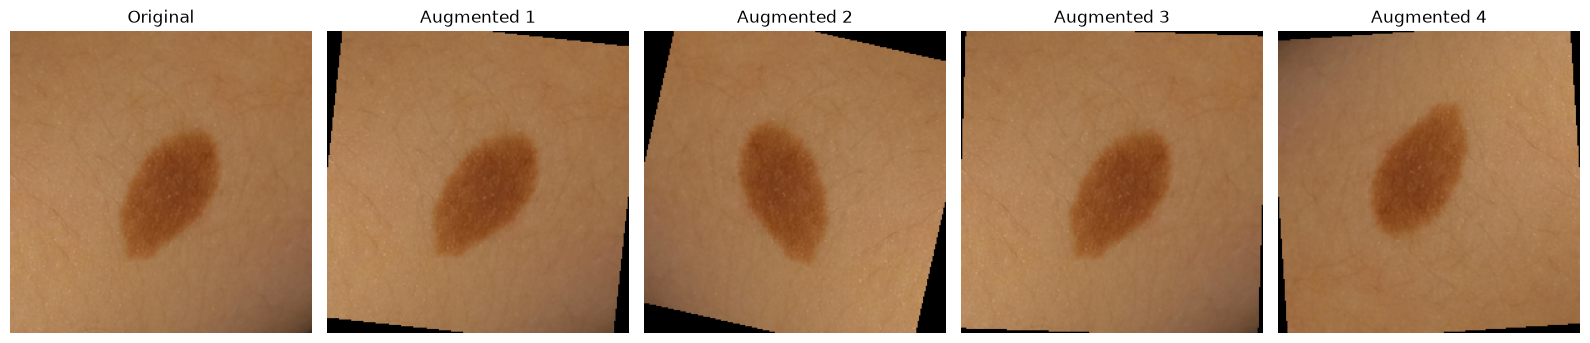

Original disease: NEV
Augmented tensor count: 4
All augmented tensors verified!


In [49]:
# PHASE 3 - STEP 12: TEST DATA AUGMENTATION

import sys
import importlib
import matplotlib.pyplot as plt

sys.path.insert(0, str(PROJECT_ROOT / "ml" / "src"))

from data import augmentations

importlib.reload(augmentations)

train_transform = augmentations.train_transform
eval_transform = augmentations.eval_transform

# Select one training image
sample_row = train_df.iloc[0]

sample_image = Image.open(
    sample_row["image_path"]
).convert("RGB")

# Generate augmented versions
augmented_images = [
    train_transform(sample_image)
    for _ in range(4)
]

# Display original and augmented images
fig, axes = plt.subplots(1, 5, figsize=(16, 4))

axes[0].imshow(sample_image)
axes[0].set_title("Original")

for i, image_tensor in enumerate(augmented_images):
    image = image_tensor.permute(1, 2, 0).numpy()

    axes[i + 1].imshow(image)
    axes[i + 1].set_title(f"Augmented {i + 1}")

for ax in axes:
    ax.axis("off")

plt.tight_layout()
plt.show()

# Verify tensor properties
for image_tensor in augmented_images:
    assert image_tensor.shape == (3, 224, 224)
    assert image_tensor.dtype == torch.float32
    assert image_tensor.min() >= 0
    assert image_tensor.max() <= 1

print("Original disease:", sample_row["diagnostic"])
print("Augmented tensor count:", len(augmented_images))
print("All augmented tensors verified!")

In [50]:
# STEP 13: CREATE DATASET OBJECTS

from torch.utils.data import DataLoader
from data.dataset import DermAIDataset

train_dataset = DermAIDataset(
    dataframe=train_df,
    transform=train_transform
)

val_dataset = DermAIDataset(
    dataframe=val_df,
    transform=eval_transform
)

test_dataset = DermAIDataset(
    dataframe=fold_test_df,
    transform=eval_transform
)

print("Training dataset:", len(train_dataset))
print("Validation dataset:", len(val_dataset))
print("Testing dataset:", len(test_dataset))

Training dataset: 1477
Validation dataset: 361
Testing dataset: 460


In [51]:
# STEP 14: CREATE DATALOADERS

BATCH_SIZE = 16

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=0,
    pin_memory=False
)

val_loader = DataLoader(
    val_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=0,
    pin_memory=False
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Testing batches:", len(test_loader))

Training batches: 93
Validation batches: 23
Testing batches: 29


In [52]:
# STEP 15: VERIFY DATALOADER BATCHES

images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)
print("Image data type:", images.dtype)
print("Label data type:", labels.dtype)

print("Minimum pixel value:", images.min().item())
print("Maximum pixel value:", images.max().item())

print("Labels in first batch:", labels.tolist())

# Verify batch
assert images.shape == (16, 3, 224, 224)
assert labels.shape == (16,)
assert images.dtype == torch.float32
assert labels.dtype == torch.int64

print("\nSUCCESS: Training DataLoader verified!")

Image batch shape: torch.Size([16, 3, 224, 224])
Label batch shape: torch.Size([16])
Image data type: torch.float32
Label data type: torch.int64
Minimum pixel value: 0.0
Maximum pixel value: 1.0
Labels in first batch: [1, 1, 1, 1, 1, 3, 1, 1, 1, 1, 0, 1, 0, 1, 5, 3]

SUCCESS: Training DataLoader verified!


In [53]:
# STEP 16: VERIFY ALL DATALOADERS

for name, loader in [
    ("Training", train_loader),
    ("Validation", val_loader),
    ("Testing", test_loader)
]:
    images, labels = next(iter(loader))

    print(f"\n{name} DataLoader")
    print("Image shape:", images.shape)
    print("Label shape:", labels.shape)

    assert images.shape[1:] == (3, 224, 224)
    assert images.shape[0] == labels.shape[0]
    assert images.dtype == torch.float32
    assert labels.dtype == torch.int64

print("\nSUCCESS: All three DataLoaders verified!")


Training DataLoader
Image shape: torch.Size([16, 3, 224, 224])
Label shape: torch.Size([16])

Validation DataLoader
Image shape: torch.Size([16, 3, 224, 224])
Label shape: torch.Size([16])

Testing DataLoader
Image shape: torch.Size([16, 3, 224, 224])
Label shape: torch.Size([16])

SUCCESS: All three DataLoaders verified!
